In [1]:
# Timer for notebook
import time
_start_time = time.perf_counter()

# Put imports here
import numpy as np
from scipy import stats, special, integrate, fft
import matplotlib.pyplot as plt
import mp3lib as ml

SEED = 690403480 # drawn 2026-11-23, do not change
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8, rng_A, rng_B = rng.spawn(10)

magnitude = 7
n = np.zeros(magnitude + 1, dtype=int)
for i in range(magnitude + 1):
    n[i] = 10 ** i

## Step 1

## Step 2

### Question 1

$\text{Let } X \sim U(-1, 1) \text{ and } Y = X^{2}$

$f_{X}(x)=\frac{1}{1-(-1)}=\frac{1}{2}$

<br>

$\mathbb{E}[X] = \int_{-1}^{+1} \frac{1}{2} x\ dx$

$\hspace{2.4em} = \frac{1}{4} [x^{2}]_{-1}^{+1}$

$\hspace{2.4em} = \frac{1}{4} [0]$

$\hspace{2.4em} = 0$

<br>

$\mathbb{E}[Y] = \int_{-1}^{+1} \frac{1}{2} x^{2}\ dx$

$\hspace{2.3em} = \frac{1}{6} [x^{3}]_{-1}^{+1}$

$\hspace{2.3em} = \frac{1}{6} [2]_{-1}^{+1}$

$\hspace{2.3em} = \frac{1}{3}$

<br>

$\mathbb{E}[XY] = \int_{-1}^{+1} \frac{1}{2} x^{3}\ dx$

$\hspace{3.2em} = \frac{1}{8} [x^{4}]_{-1}^{+1}$

$\hspace{3.2em} = \frac{1}{8} [0]$

$\hspace{3.2em} = 0$

<br>

$\text{Cov}(X, Y) = \mathbb{E}[XY] - \mathbb{E}[X]\mathbb{E}[Y]$

$\hspace{5em} = (0) - (0)(\frac{1}{3})$

$\hspace{5em} = 0$

### Question 2

In [88]:
X = rng_2.uniform(-1, 1, size=n[7])
Y = X ** 2
[varx, cov], [_, vary] = ml.sample_mean_cov(np.stack((X, Y), axis=1))[1]
corr = cov / np.sqrt(varx * vary)
se_r = np.sqrt((1 - corr**2) / (n[7] - 2))

print(f"Cov(X,Y) = {cov:.5f}\n" +
      f"Var(X) = {varx:.5f}, Var(Y) = {vary:.5f}\n")

print(f"Corr(X,Y) = {corr:.5f}\n" +
      f"SE(Corr(X,Y)) = {se_r:.5f}")

Cov(X,Y) = -0.00007
Var(X) = 0.33339, Var(Y) = 0.08892

Corr(X,Y) = -0.00041
SE(Corr(X,Y)) = 0.00032


### Question 3

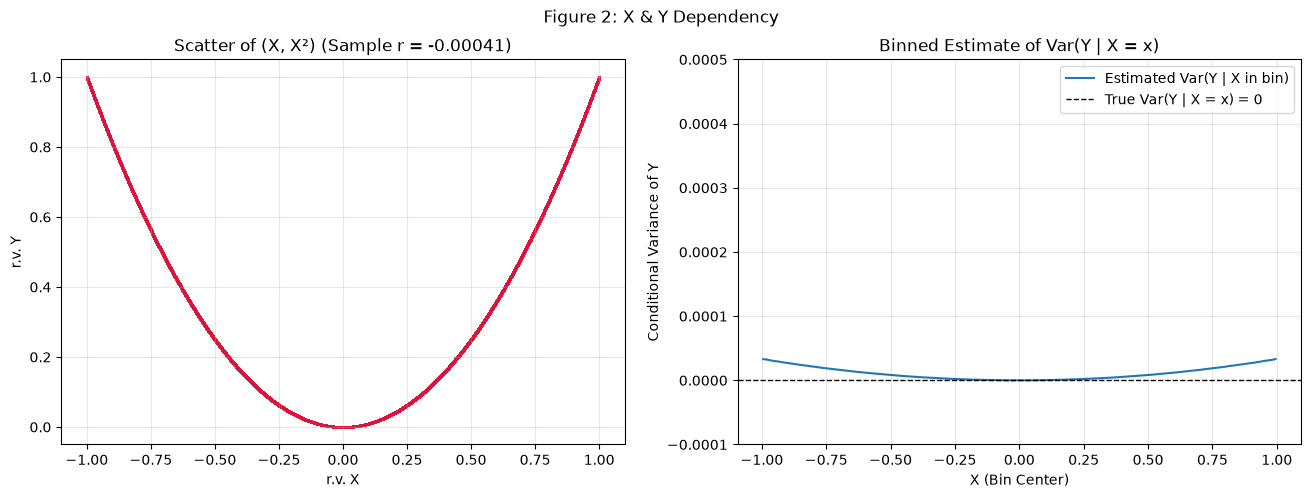

Bin width h = 0.0100

Max binned variance (L_inf): 3.3195e-05
RMS binned variance (L_2):   1.4907e-05
Mean binned variance:        1.1112e-05 (0.0125% of Var(Y))


In [ ]:
binned_var, bin_edges, _ = stats.binned_statistic(X, Y, statistic=lambda y: np.var(y, ddof=1), bins=200)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].scatter(X, Y, color='crimson', marker='o', s=1)
axes[0].set_title(f"Scatter of (X, X\u00b2) (Sample r = {corr:.5f})")
axes[0].set_xlabel("r.v. X")
axes[0].set_ylabel("r.v. Y")
axes[0].grid(True, alpha=0.3)

axes[1].plot(bin_centers, binned_var, label="Estimated Var(Y | X in bin)")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1, label="True Var(Y | X = x) = 0")
axes[1].set_title("Binned Estimate of Var(Y | X = x)")
axes[1].set_xlabel("X (Bin Center)")
axes[1].set_ylabel("Conditional Variance of Y")
axes[1].set_ylim(-0.0001, 0.0005)  # Shows how close to 0 it is relative to Var(Y) ≈ 0.089
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.suptitle("Figure 2: X & Y Dependency")

plt.show()

h = 2.0 / len(binned_var)

max_var = np.max(binned_var)  # L-infinity norm
rms_var = np.sqrt(np.mean(binned_var**2))  # Normalized L2 norm
mean_var = np.mean(binned_var)  # Average E[Var(Y | X in bin)]
unexplained_ratio = mean_var / np.var(Y)  # Fraction of total Var(Y) = 4/45

print(f"Bin width h = {h:.4f}\n")

print(f"Max binned variance (L_inf): {max_var:.4e}")
print(f"RMS binned variance (L_2):   {rms_var:.4e}")
print(f"Mean binned variance:        {mean_var:.4e} ({unexplained_ratio:.4%} of Var(Y))")

### Question 4

The correlation coefficent measures the strength and direction of two variables linear relationship, meaning that it fails to measure nonlinear relationships such as this, where Y at points has negative slope when X's slope is positive.

### Question 5

In [97]:
data=np.random.multivariate_normal([0, 0], [[1, 0], [0, 1]], size=n[7])
x, y = data[:, 0], data[:, 1]

bins = 40
range_lims = [[-4, 4], [-4, 4]]

# Empirical joint density f_{X,Y}(x, y)
joint_hist, x_edges, y_edges = np.histogram2d(
    x, y, bins=bins, range=range_lims, density=True
)

# Empirical marginal densities f_X(x) and f_Y(y)
x_hist, _ = np.histogram(x, bins=x_edges, density=True)
y_hist, _ = np.histogram(y, bins=y_edges, density=True)

# Product of marginals: f_X(x) * f_Y(y)
prod_marginals = np.outer(x_hist, y_hist)

# quantify agreement
abs_diff = np.abs(joint_hist - prod_marginals)
mae = np.mean(abs_diff)
rmse = np.sqrt(np.mean((joint_hist - prod_marginals) ** 2))
max_err = np.max(abs_diff)

# Bin area (dx * dy) for integral-based metrics
dx = x_edges[1] - x_edges[0]
dy = y_edges[1] - y_edges[0]

# Total Variation Distance (TVD): 0.5 * \iint |f_{X,Y} - f_X f_Y| dx dy
tvd = 0.5 * np.sum(abs_diff) * dx * dy

# Kullback-Leibler (KL) Divergence / Mutual Information: D_KL(P_{X,Y} || P_X P_Y)
mask = (joint_hist > 0) & (prod_marginals > 0)
kl_div = np.sum(joint_hist[mask] * np.log(joint_hist[mask] / prod_marginals[mask])) * dx * dy

# Sample Pearson correlation
sample_corr = stats.pearsonr(x, y)[0]

print(f"Sample Pearson r:                     {sample_corr:.6f}")
print(f"Mean Absolute Error (MAE):            {mae:.6f}")
print(f"Root Mean Squared Error (RMSE):       {rmse:.6f}")
print(f"Max Absolute Error:                   {max_err:.6f}")
print(f"Total Variation Distance (TVD):       {tvd:.6f}")
print(f"KL Divergence (Mutual Information):   {kl_div:.6e} nats")

Sample Pearson r:                     0.000033
Mean Absolute Error (MAE):            0.000099
Root Mean Squared Error (RMSE):       0.000204
Max Absolute Error:                   0.001587
Total Variation Distance (TVD):       0.003175
KL Divergence (Mutual Information):   7.775888e-05 nats


### Question 6

Because a jointly Gaussian distribution is completely determined by its mean vector and covariance matrix, zero covariance causes the joint PDF to factor directly into the product of its marginal densities, guaranteeing independence. In general, however, correlation only captures linear relationships, meaning non-Gaussian variables can have zero covariance while remaining strongly dependent through nonlinear patterns (such as Y = X^2 in questions 1-4 of this step). This makes the Gaussian assumption load-bearing because it allows Kalman filters, linear estimators and other such methods high degrees of statistical accuracy using only second-order properties (mean/covariance), while preventing unfeasible computation hurdles (such as tracking entire distributions).

## Step 3

## Step 4

## Step 5

## Step 6

## Step 7

## Step 8

## Bonus A

## Bonus B

In [ ]:
_end_time = time.perf_counter()
print(f"Total Notebook Runtime: {_end_time - _start_time:.3f} seconds")